In [1]:
import os

PATH = '/kaggle/input/datasets/mdsifatullahsheikh/medicinal-plant-leaf-images-13-species/A Medicinal Plant Leaf Image Dataset of 13 Species/A Medicinal Plant Leaf Image Dataset of 13 Species/Dataset/Dataset/Madicinal_Leaf_Dataset/CapC_Madicinal_Leaf_Dataset'

os.listdir(path=PATH)

['Azadirachta_Indica',
 'Calotropis_Gigantea',
 'Datura_Metel',
 'Gynura_Procumbens',
 'Heliotropium_Angiospermum',
 'Jatropha_Gossypiifolia',
 'Justicia_Adhatoda',
 'Mikania_Micrantha',
 'Polyalthia_longifolia',
 'Rauvolfia_Tetraphylla',
 'Sida_Rhombifolia',
 'Smilax_Zeylanica',
 'Wissadula_Periplocifolia']

We want to use ResNeXt image embeddings for EDA and classification, so let's add some code to get them for us.

In [2]:
import torch
import torchvision.models as models
import torchvision.transforms as transforms
import numpy as np


DEVICE = torch.device('cpu')
OUTPUT_SIZE = 2048

model = models.resnext50_32x4d(weights=models.ResNeXt50_32X4D_Weights.IMAGENET1K_V2)

extraction_layer = model._modules.get('avgpool')
model.to(DEVICE)
model.eval()

scaler = transforms.Resize((224, 224))
normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
to_tensor = transforms.ToTensor()

def get_vec(arg, model, extraction_layer):
    image = normalize(to_tensor(scaler(arg))).unsqueeze(0).to(DEVICE)
    result = torch.zeros(1, OUTPUT_SIZE, 1, 1)
    def copy_data(m, i, o):
        result.copy_(o.data)
    hooked = extraction_layer.register_forward_hook(copy_data)
    with torch.no_grad():
        model(image)
    hooked.remove()
    return result

Downloading: "https://download.pytorch.org/models/resnext50_32x4d-1a0047aa.pth" to /root/.cache/torch/hub/checkpoints/resnext50_32x4d-1a0047aa.pth


100%|██████████| 95.8M/95.8M [00:00<00:00, 155MB/s]


Let's load up our data, no matter how long it takes (less than twenty minutes).

In [3]:
import arrow
import base64
import pandas as pd
import tqdm

from glob import iglob
from io import BytesIO
from os.path import basename
from os.path import isdir
from PIL import Image

THUMBNAIL_SIZE = (48, 48)

def embed(model, filename: str):
    try:
        with Image.open(fp=filename, mode='r') as image:
            return get_vec(arg=image.convert('RGB'), model=model, extraction_layer=extraction_layer).numpy().reshape(OUTPUT_SIZE,)
    except: 
        print(filename)
        return None


# https://stackoverflow.com/a/952952
def flatten(arg):
    return [x for xs in arg for x in xs]

def png(filename: str) -> str:
    with Image.open(fp=filename, mode='r') as image:
        buffer = BytesIO()
        image.resize(size=THUMBNAIL_SIZE).convert('RGB').save(buffer, format='png')
        return 'data:image/png;base64,' + base64.b64encode(buffer.getvalue()).decode()

def get_picture_from_glob(arg: str, tag: str,) -> list:
    input_files = list(iglob(pathname=arg))
    input_files = [item for item in input_files if (item.endswith('.jpg') or item.endswith('.JPG'))]
    result = [pd.Series(data=[tag, basename(input_file), embed(model=model, filename=input_file), png(filename=input_file)],
                        index=['tag', 'name', 'value', 'png'])
        for index, input_file in enumerate(tqdm.tqdm(desc=tag, iterable=input_files)) ]
    return result

time_start = arrow.now()
train_dict = {basename(folder) : folder + '/*.*' for folder in iglob(PATH + '/*') if isdir(folder) }
train_df = pd.DataFrame(data=flatten(arg=[get_picture_from_glob(arg=value, tag=key) for (key, value) in train_dict.items()]))
train_df['tag'] = train_df['tag'].str.replace('_', ' ')
print('done in {}'.format(arrow.now() - time_start))

Wissadula_Periplocifolia: 100%|██████████| 242/242 [00:51<00:00,  4.73it/s]


done in 0:13:58.621285


Our classes are not balanced, but they're all well-represented.

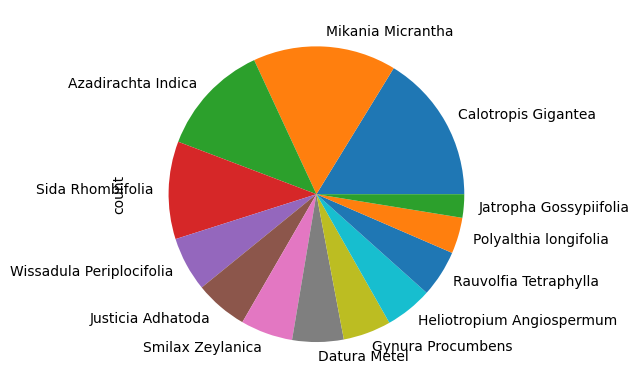

In [4]:
import matplotlib.pyplot as plt

train_df['tag'].value_counts().to_frame().plot(kind='pie', subplots=True, legend=False)
plt.show()

Next let's use TSNE to add x/y coordinates based on our image embeddings.

In [5]:
from sklearn.manifold import TSNE

train_reducer = TSNE(random_state=2026, verbose=True, n_jobs=1, perplexity=20.0, init='pca')
train_df[['x', 'y']] = train_reducer.fit_transform(X=train_df['value'].apply(func=pd.Series))

[t-SNE] Computing 61 nearest neighbors...
[t-SNE] Indexed 4063 samples in 0.029s...
[t-SNE] Computed neighbors for 4063 samples in 1.598s...
[t-SNE] Computed conditional probabilities for sample 1000 / 4063
[t-SNE] Computed conditional probabilities for sample 2000 / 4063
[t-SNE] Computed conditional probabilities for sample 3000 / 4063
[t-SNE] Computed conditional probabilities for sample 4000 / 4063
[t-SNE] Computed conditional probabilities for sample 4063 / 4063
[t-SNE] Mean sigma: 2.963796
[t-SNE] KL divergence after 250 iterations with early exaggeration: 63.774658
[t-SNE] KL divergence after 1000 iterations: 0.565808


First let's make a static plot with our thumbnails, just as a first look.

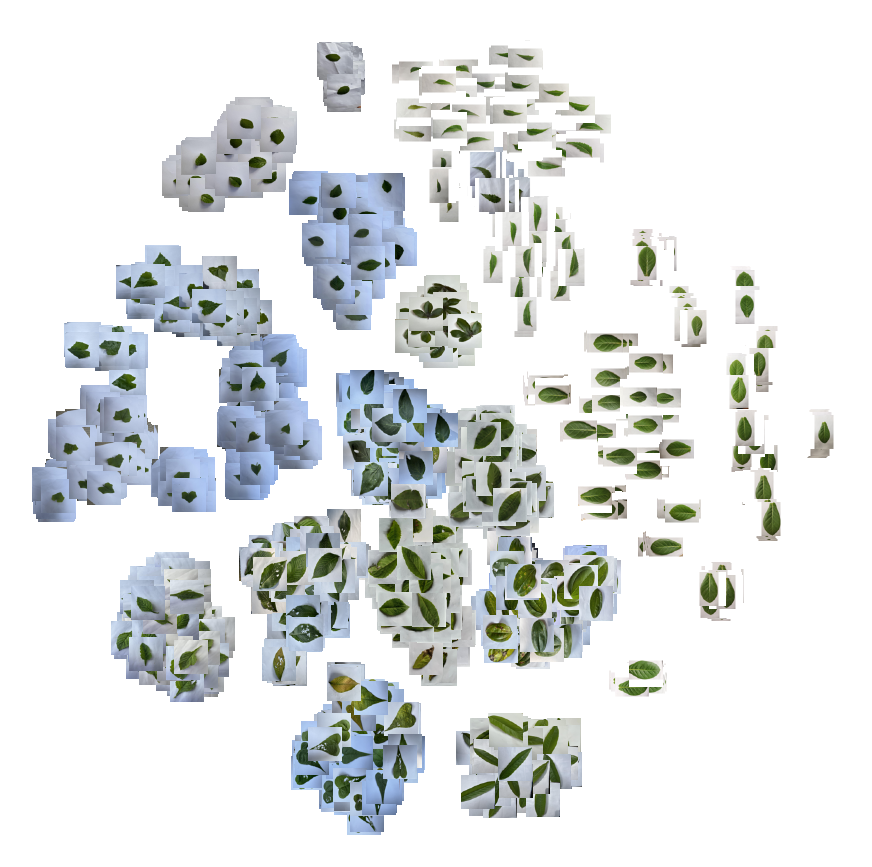

In [6]:
import base64
import io
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.offsetbox import AnnotationBbox, OffsetImage
from PIL import Image

# we recycled some PNG encoding code above, and we need to postprocess it for using with matplotlib
train_df['PNG'] = train_df['png'].str.replace('^data:image/png;base64,', '', regex=True)
plot_df = train_df.sample(n=2500, random_state=2026) if len(train_df) > 2501 else train_df.copy()
fig, ax = plt.subplots(figsize=(11, 11))

for index, row in plot_df.iterrows():
    img_bytes = base64.b64decode(row["PNG"])
    img = Image.open(io.BytesIO(img_bytes))
    imagebox = OffsetImage(img, zoom=0.5)
    ab = AnnotationBbox(imagebox, (row["x"], row["y"]), frameon=False, pad=0)
    ax.add_artist(ab)
ax.scatter(plot_df["x"], plot_df["y"], alpha=0)
ax.axis('off')
plt.show()

What do we see? It looks like our data has been augmented, a lot actually, but as a result we have fairly isolated, sometimes tight clusters. Let's make an exploratory plot.

In [7]:
from bokeh.models import ColumnDataSource
from bokeh.models import HoverTool

from bokeh.plotting import figure
from bokeh.plotting import output_notebook
from bokeh.plotting import show
from bokeh.palettes import Turbo256
from bokeh.transform import factor_cmap

output_notebook()

datasource = ColumnDataSource(train_df[['png', 'tag', 'x', 'y']].sample(n=min(len(train_df) - 1, 10000)))
factor_count = max(train_df['tag'].nunique(), 3)
indices = np.linspace(0, len(Turbo256)-1, factor_count, dtype=int)
palette = [Turbo256[index] for index in indices]
mapper = factor_cmap(field_name = 'tag', palette=palette, factors=train_df['tag'].unique().tolist(), start=0, end=factor_count-1, )

plot_figure = figure(title='TSNE projection: medicinal leaves', width=1000, height=800, tools=('pan, wheel_zoom, reset'))

plot_figure.add_tools(HoverTool(tooltips="""
<div>
    <div>
        <img src='@png' style='float: left; margin: 5px 5px 5px 5px'/>
    </div>
    <div>
        <span style='font-size: 18px'>@tag</span>
    </div>
</div>
"""))

plot_figure.scatter(x='x', y='y', source=datasource, line_alpha=0.6, fill_alpha=0.6, size=8, color=mapper)
show(plot_figure)

Loading BokehJS ...

What do we see? We see that all of our data is in tight local clusters, some of which cluster into class clusters. Let's build a model.

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(train_df['value'].apply(pd.Series), train_df['tag'], test_size=0.2, random_state=2026, stratify=train_df['tag'])
logreg = LogisticRegression(max_iter=10000, tol=1e-12).fit(X_train, y_train)
print('model fit in {} iterations'.format(logreg.n_iter_[0]))
print('accuracy: {:5.4f}'.format(accuracy_score(y_true=y_test, y_pred=logreg.predict(X=X_test))))
print('f1: {:5.4f}'.format(f1_score(average='weighted', y_true=y_test, y_pred=logreg.predict(X=X_test))))
print(classification_report(y_true=y_test, y_pred=logreg.predict(X=X_test), zero_division=0.0))

model fit in 671 iterations
accuracy: 1.0000
f1: 1.0000
                           precision    recall  f1-score   support

       Azadirachta Indica       1.00      1.00      1.00       100
      Calotropis Gigantea       1.00      1.00      1.00       132
             Datura Metel       1.00      1.00      1.00        46
        Gynura Procumbens       1.00      1.00      1.00        43
Heliotropium Angiospermum       1.00      1.00      1.00        42
   Jatropha Gossypiifolia       1.00      1.00      1.00        21
        Justicia Adhatoda       1.00      1.00      1.00        47
        Mikania Micrantha       1.00      1.00      1.00       127
    Polyalthia longifolia       1.00      1.00      1.00        32
    Rauvolfia Tetraphylla       1.00      1.00      1.00        42
         Sida Rhombifolia       1.00      1.00      1.00        87
         Smilax Zeylanica       1.00      1.00      1.00        46
 Wissadula Periplocifolia       1.00      1.00      1.00        48

    

Zero misclassifications is nice. Let's look at our model probabilities.

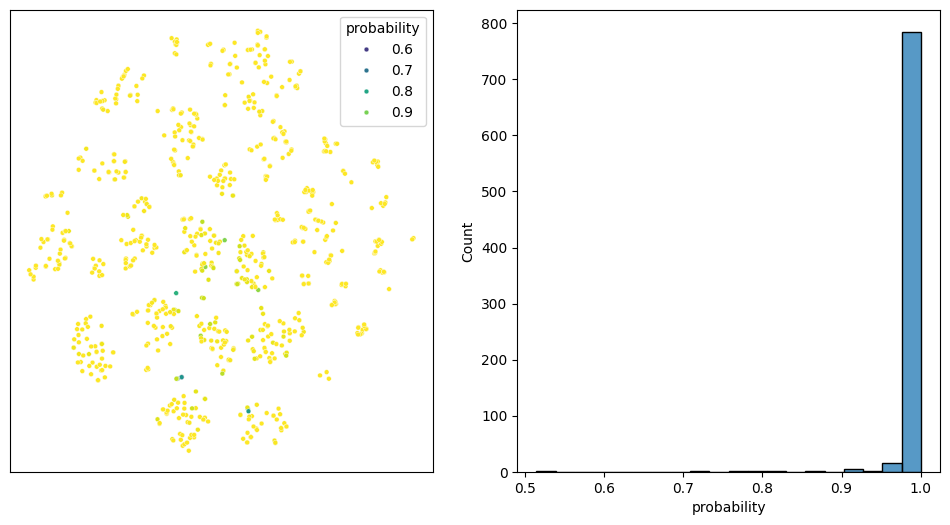

In [9]:
import warnings
from seaborn import histplot
from seaborn import scatterplot

warnings.filterwarnings('ignore', category=FutureWarning, module='seaborn')

plot_df = train_df.iloc[X_test.index][['x', 'y']].copy()
plot_df['probability'] = np.max(logreg.predict_proba(X=X_test), axis=1)

fig, ax = plt.subplots(ncols=2, figsize=(12, 6))
scatterplot(ax=ax[0], data=plot_df, x='x', y='y', hue='probability', palette='viridis', s=12)
ax[0].set(xlabel=None) 
ax[0].set(ylabel=None)
ax[0].set(xticklabels=[])
ax[0].set(yticklabels=[])
ax[0].tick_params(axis='both', which='both', length=0)
histplot(ax=ax[1], data=plot_df, x='probability', bins=20)
fig.show()

All of our model probabilities are high; most of them are very high. Yay!